# 2. What the signals look like

Before any classifier we look at the spectra of our two first datasets:

- **Cluster**: a machine slides a probe on 72 surfaces at 5 speeds;
- **LMT108**: a person slides a steel tip by hand on 36 surfaces.

Both have the sound (microphone) and the vibration (accelerometer) of each scrape.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import ndimage, signal
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

FAMILIES = ["wood", "metal", "textile", "polymer"]
COLORS = {"wood": "tab:blue", "metal": "tab:orange", "textile": "tab:green", "polymer": "tab:olive"}

## The data

`1_data.ipynb` computes one power spectrum per recording (Welch), for the sound and for the vibration.

In [2]:
saved = np.load("cache/spectra.npz", allow_pickle=True)
spectra = {"sound": saved["sound"], "vibration": saved["vibration"]}
info = pd.DataFrame({c: saved[c] for c in saved.files if c not in spectra})

FREQ = {"sound": np.fft.rfftfreq(8192, 1 / 44100)[:2049], "vibration": np.fft.rfftfreq(1600, 1 / 8000)}
BAND = {"sound": (100, 8000), "vibration": (10, 600)}

info.groupby("dataset").agg(recordings=("family", "size"), surfaces=("surface", "nunique"))

,recordings,surfaces
dataset,,
cluster,11520,72
lmt108,720,36


## Machine noise in Cluster

We take the median spectrum of all the Cluster surfaces at each speed. What is common to all surfaces is probably
not the surface. If we plot against frequency / speed, the peaks line up: they sit at multiples of 0.875 per mm,
so f = 3.5 x speed for the strongest one. This looks like the drive of the machine.

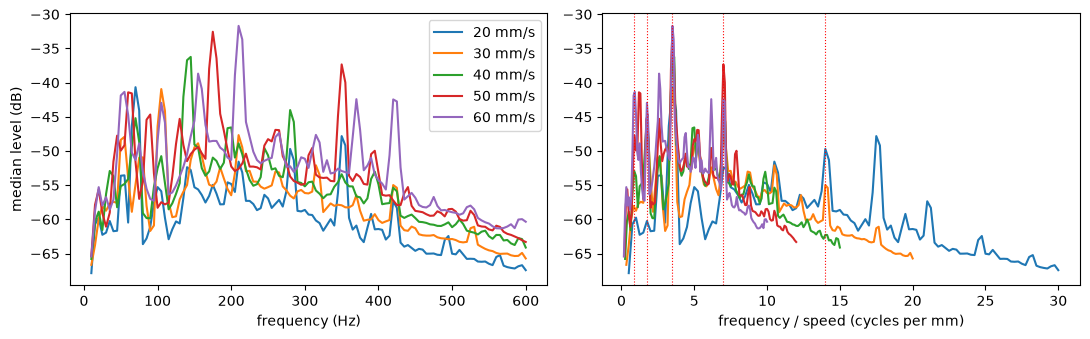

In [3]:
cluster = (info.dataset == "cluster").to_numpy()
speeds = [20, 30, 40, 50, 60]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for v in speeds:
    median = np.median(spectra["vibration"][cluster & (info.velocity == v).to_numpy()], axis=0)
    shown = (FREQ["vibration"] >= 10) & (FREQ["vibration"] <= 600)
    axes[0].plot(FREQ["vibration"][shown], 10 * np.log10(median[shown]), label=f"{v} mm/s")
    axes[1].plot(FREQ["vibration"][shown] / v, 10 * np.log10(median[shown]))
for k in [0.875, 1.75, 3.5, 7, 14]:
    axes[1].axvline(k, color="red", linestyle=":", linewidth=0.8)
axes[0].set_xlabel("frequency (Hz)")
axes[1].set_xlabel("frequency / speed (cycles per mm)")
axes[0].set_ylabel("median level (dB)")
axes[0].legend()
plt.tight_layout()
plt.savefig("results/signals_machine_lines.png", dpi=120)

In [4]:
# share of the 10-600 Hz vibration energy that sits within 10 Hz of a multiple of 3.5 x speed
for v in speeds:
    median = np.median(spectra["vibration"][cluster & (info.velocity == v).to_numpy()], axis=0)
    f = FREQ["vibration"]
    in_band = (f >= 10) & (f <= 600)
    near_line = np.abs(f / (3.5 * v) - np.round(f / (3.5 * v))) * 3.5 * v <= 10
    print(v, "mm/s:", round(median[in_band & near_line].sum() / median[in_band].sum(), 2))

20 mm/s: 0.73
30 mm/s: 0.45
40 mm/s: 0.61
50 mm/s: 0.63
60 mm/s: 0.54


For the rest we remove these lines: at each speed we find the narrow peaks of the median spectrum (more than 5 dB
above their neighbours) and replace them by a straight line between their two sides.

In [5]:
def without_machine_lines(kind, filter_width):
    clean = spectra[kind].copy()
    in_band = (FREQ[kind] >= BAND[kind][0]) & (FREQ[kind] <= BAND[kind][1])
    for v in speeds:
        rows = np.flatnonzero(cluster & (info.velocity == v).to_numpy())
        level = 10 * np.log10(np.median(spectra[kind][rows], axis=0))
        prominence = level - ndimage.median_filter(level, filter_width)
        peaks, _ = signal.find_peaks(np.where(in_band, prominence, 0), height=5)
        masked = np.zeros(len(level), dtype=bool)
        for peak in peaks:
            masked[peak - 2 : peak + 3] = True
        log_power = pd.DataFrame(np.log(spectra[kind][rows]))
        log_power.loc[:, masked] = np.nan
        clean[rows] = np.exp(log_power.interpolate(axis=1).to_numpy())
    return clean


clean = {"sound": without_machine_lines("sound", 41), "vibration": without_machine_lines("vibration", 15)}

## Spectral shapes

To compare recordings we sum the power in third-octave bands, in dB, and remove the mean level of each recording.
What is left is the **shape** of the spectrum, not how loud it is.

In [6]:
def third_octaves(power, freq, low, high):
    centers = 1000 * 2.0 ** (np.arange(-30, 30) / 3)
    centers = centers[(centers / 2 ** (1 / 6) >= low) & (centers * 2 ** (1 / 6) <= high)]
    levels = {}
    for c in centers:
        inside = (freq >= c / 2 ** (1 / 6)) & (freq < c * 2 ** (1 / 6))
        if inside.sum() >= 2:
            levels[int(round(c))] = 10 * np.log10(power[:, inside].sum(axis=1))
    return pd.DataFrame(levels)


parts = []
for kind in ["sound", "vibration"]:
    levels = third_octaves(clean[kind], FREQ[kind], *BAND[kind])
    parts.append(levels.sub(levels.mean(axis=1), axis=0).add_prefix(kind + " "))
shapes = pd.concat(parts, axis=1)

pd.concat([info, shapes], axis=1).to_csv("cache/spectral_shapes.csv", index=False)
shapes.shape

(12240, 30)

## Do the families look different?

Median shape of each family, in each dataset.

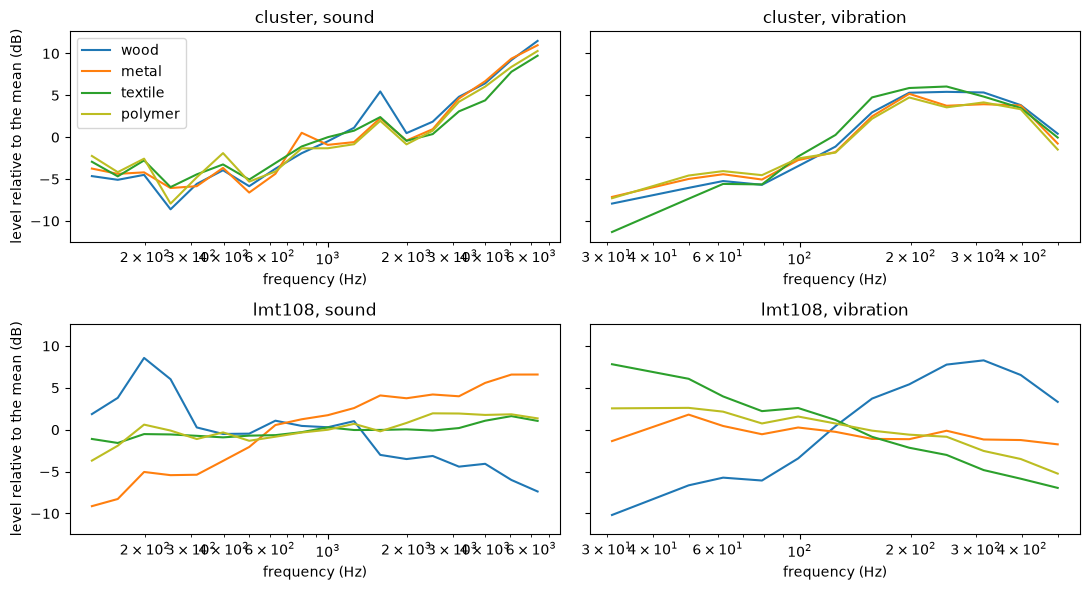

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharey=True)
for i, dataset in enumerate(["cluster", "lmt108"]):
    for j, kind in enumerate(["sound", "vibration"]):
        columns = [c for c in shapes.columns if c.startswith(kind)]
        bands = [int(c.split()[1]) for c in columns]
        for family in FAMILIES:
            rows = ((info.dataset == dataset) & (info.family == family)).to_numpy()
            per_surface = shapes.loc[rows, columns].groupby(info.surface[rows].to_numpy()).median()
            axes[i, j].plot(bands, per_surface.median(), color=COLORS[family], label=family)
        axes[i, j].set_xscale("log")
        axes[i, j].set_title(f"{dataset}, {kind}")
        axes[i, j].set_xlabel("frequency (Hz)")
    axes[i, 0].set_ylabel("level relative to the mean (dB)")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("results/signals_family_spectra.png", dpi=120)

## Family or dataset?

A PCA of all the shapes. For Cluster we keep one direction and one force so both datasets weigh about the same.

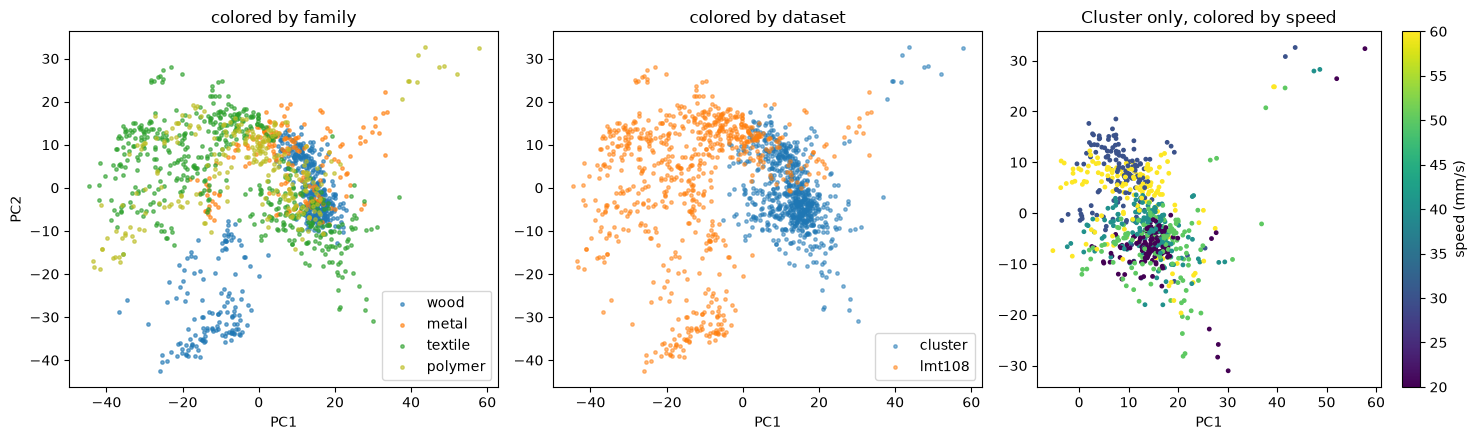

In [8]:
kept = ((info.dataset == "lmt108") | ((info.direction == 0) & (info.force == 500))).to_numpy()
points = info[kept].reset_index(drop=True)
xy = PCA(2).fit_transform(shapes[kept])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for family in FAMILIES:
    rows = (points.family == family).to_numpy()
    axes[0].scatter(xy[rows, 0], xy[rows, 1], s=6, alpha=0.6, color=COLORS[family], label=family)
for dataset in ["cluster", "lmt108"]:
    rows = (points.dataset == dataset).to_numpy()
    axes[1].scatter(xy[rows, 0], xy[rows, 1], s=6, alpha=0.5, label=dataset)
rows = (points.dataset == "cluster").to_numpy()
dots = axes[2].scatter(xy[rows, 0], xy[rows, 1], s=6, c=points.velocity[rows], cmap="viridis")
plt.colorbar(dots, ax=axes[2], label="speed (mm/s)")
for ax, title in zip(axes, ["colored by family", "colored by dataset", "Cluster only, colored by speed"]):
    ax.set_title(title)
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.savefig("results/signals_pca.png", dpi=120)

The same question with numbers: we cluster the surfaces with k-means (one median shape per surface) and compare
the groups with the families and with the datasets. The adjusted Rand index is 1 for a perfect match and 0 for
random groups.

In [9]:
per_surface = shapes.groupby([info.dataset, info.family, info.surface]).median()
labels = per_surface.index.to_frame(index=False)
rows = []
for k in [2, 3, 4]:
    groups = KMeans(k, n_init=20, random_state=0).fit_predict(per_surface)
    rows.append(
        {
            "k": k,
            "match with dataset": adjusted_rand_score(labels.dataset, groups),
            "match with family": adjusted_rand_score(labels.family, groups),
        }
    )
pd.DataFrame(rows).set_index("k").round(2)

,match with dataset,match with family
k,,
2,0.89,0.05
3,0.83,0.08
4,0.80,0.09


## What does speed do?

If speed only moved the frequencies (same bumps of the surface read faster), the spectrum at 60 mm/s would be the
spectrum at 20 mm/s shifted by a factor 3. We compare, for the same surface, the spectrum at 20 and at 60 mm/s:

- at the same frequency;
- at the same frequency / speed.

In [10]:
rows = []
for kind in ["sound", "vibration"]:
    grid = np.geomspace(BAND[kind][0], BAND[kind][1] / 3, 200)
    for _, group in info[cluster].groupby(["surface", "direction", "force", "repeat"]):
        slow = group.index[group.velocity == 20][0]
        fast = group.index[group.velocity == 60][0]
        at_20 = np.interp(grid, FREQ[kind], np.log(clean[kind][slow]))
        at_60 = np.interp(grid, FREQ[kind], np.log(clean[kind][fast]))
        at_60_shifted = np.interp(3 * grid, FREQ[kind], np.log(clean[kind][fast]))
        level = "audio_log_rms" if kind == "sound" else "accel_log_rms"
        rows.append(
            {
                "signal": kind,
                "same frequency": np.corrcoef(at_20, at_60)[0, 1],
                "same frequency / speed": np.corrcoef(at_20, at_60_shifted)[0, 1],
                "dB per doubling of speed": 20 * (info[level][fast] - info[level][slow]) / np.log2(3),
            }
        )
pd.DataFrame(rows).groupby("signal").median().round(2)

,same frequency,same frequency / speed,dB per doubling of speed
signal,,,
sound,0.45,0.02,5.37
vibration,0.29,0.08,5.58


## What we see

- The two datasets differ much more than the four families: a PCA or a clustering finds the dataset, not the family.
- Inside LMT108 the families do have different shapes. In Cluster they look almost the same.
- The Cluster vibration contains lines that follow the speed of the machine. We remove them before going on.
- Speed is not a simple shift of the frequencies: spectra match better at the same frequency. The level rises by a
  few dB each time the speed doubles.

For the models this means: remove the level, and do not expect a model trained on one dataset to work on the other.